# [title] Two-state Model: the Simulator and the Prior

**Question.** Do `simulate_sitting` and `sample_prior` produce what
[decision 0008](../../docs/decisions/0008-two-state-model.md) says, and do the Sittings
they lead to look like those of real experiments? Terms: [glossary](../../docs/glossary.md).

**Scope.** The second pull request of
[#28](https://github.com/opherdonchin/MotorAdpatationSBI/issues/28). The Model is written
up in [docs/models/two_state.md](../../docs/models/two_state.md); the code is in
[`src/models/two_state.py`](../../src/models/two_state.py). The cells follow the two
one-state working notebooks (the Simulator's and the Prior's), with the two-state Model.

**Checks:**

1. *The link to the one-state Model.* When the two retentions are equal, the movements
   are those of the one-state Model with adaptation rate $B_f + B_s$ and planning noise
   $\sqrt 2\,\sigma_\eta$: exactly without noise, and in their steady-state statistics
   with noise.
2. *It behaves like a two-state model.* Without noise the states follow the closed-form
   solution of the two linear recursions, and after a short reversal the movement
   recovers spontaneously. With noise, the steady-state standard deviation and lag-1
   correlation match those computed from the Model by linear algebra.
3. *The Prior.* Each quantity's central 95% interval is the one in the decision's table;
   then simulated Sittings, for Opher to judge by eye.

In [1]:
# [imports]
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import linalg, special, stats

from designs import visuomotor_adaptation_experiment as des
from models import one_state
from models import two_state as mdl

In [2]:
# [config] Root seed, example Sitting, Prior and Schedule Design constants, sizes of the Checks
root_seed = 15076981454491607406712533078155144610  # secrets.randbits(128)

# theta = (Af, As, Bf, Bs, s_eta, s_epsilon), in units of the
# perturbation size. The four rates are those of Smith et al. (2006).
theta_example = (0.59, 0.992, 0.21, 0.02, 0.02, 0.15)
example_blocks = [("baseline", 40), ("+1", 200), ("-1", 12), ("no vision", 60), ("baseline", 40)]
tiny = 1e-12  # noise standard deviation that makes a Sitting deterministic

# Check 1: one retention for both states, and the two adaptation rates.
equal_A, equal_Bf, equal_Bs = 0.95, 0.15, 0.05

# Parameter sets for the steady-state Checks. The first has (nearly) equal retentions,
# so the one-state formulas apply to it as well.
stationary_thetas = [
    (equal_A, np.nextafter(equal_A, 1), equal_Bf, equal_Bs, 0.03, 0.15),
    (0.59, 0.992, 0.21, 0.02, 0.02, 0.15),
    (0.8, 0.98, 0.3, 0.05, 0.03, 0.1),
    (0.4, 0.995, 0.1, 0.01, 0.01, 0.2),
]
n_sittings = 2000  # independent Sittings per parameter set and condition
t_burn = 1500  # Trials discarded first, until the start no longer matters
t_keep = 800  # Trials kept per Sitting for the statistics
n_batches = 20  # groups of Sittings, for the Monte Carlo standard errors

# Decision 0008, step 1: the central 95% range of each rate, as a number between 0 and 1.
range_Af = (0.70, 0.90)
range_As = (0.95, 0.999)
range_Bf = (0.10, 0.35)
range_Bs = (0.001, 0.05)
range_s_epsilon = (1 / 15, 1 / 3)
range_ratio = (1 / 15, 1 / 5)  # s_eta / s_epsilon
range_block_len = (10, 250)  # trials

# Step 2: each range as a normal on the logit scale (mean halfway between the logits of
# the two ends; standard deviation their distance over 2 * 1.96).
z95 = stats.norm.ppf(0.975)
mu_logit_Af, sigma_logit_Af = special.logit(range_Af).mean(), np.ptp(special.logit(range_Af)) / (2 * z95)
mu_logit_As, sigma_logit_As = special.logit(range_As).mean(), np.ptp(special.logit(range_As)) / (2 * z95)
mu_logit_Bf, sigma_logit_Bf = special.logit(range_Bf).mean(), np.ptp(special.logit(range_Bf)) / (2 * z95)
mu_logit_Bs, sigma_logit_Bs = special.logit(range_Bs).mean(), np.ptp(special.logit(range_Bs)) / (2 * z95)

# Step 3: the slow rates through positive differences, d_A = logit(As) - logit(Af) and
# d_B = logit(Bf) - logit(Bs). Each difference gets the mean and variance that give the
# slow rate's logit the mean and variance of step 2, and is log-normal with them.
mean_d_A, var_d_A = mu_logit_As - mu_logit_Af, sigma_logit_As**2 - sigma_logit_Af**2
mean_d_B, var_d_B = mu_logit_Bf - mu_logit_Bs, sigma_logit_Bs**2 - sigma_logit_Bf**2
sigma_log_d_A = np.sqrt(np.log(1 + var_d_A / mean_d_A**2))
sigma_log_d_B = np.sqrt(np.log(1 + var_d_B / mean_d_B**2))

prior = {
    "mu_logit_Af": mu_logit_Af, "sigma_logit_Af": sigma_logit_Af,
    "mu_log_d_A": np.log(mean_d_A) - sigma_log_d_A**2 / 2, "sigma_log_d_A": sigma_log_d_A,
    "mu_logit_Bf": mu_logit_Bf, "sigma_logit_Bf": sigma_logit_Bf,
    "mu_log_d_B": np.log(mean_d_B) - sigma_log_d_B**2 / 2, "sigma_log_d_B": sigma_log_d_B,
    "mu_log_s_epsilon": np.log(range_s_epsilon).mean(),
    "sigma_log_s_epsilon": np.ptp(np.log(range_s_epsilon)) / (2 * z95),
    "mu_log_ratio": np.log(range_ratio).mean(), "sigma_log_ratio": np.ptp(np.log(range_ratio)) / (2 * z95),
}
schedule_design = {
    "n_blocks_min": 5, "n_blocks_max": 16,
    "mu_log_block_len": np.log(range_block_len).mean(),
    "sigma_log_block_len": np.ptp(np.log(range_block_len)) / (2 * z95),
    "trial_type_concentration": 3.0,
}

n_prior_draws = 1_000_000  # enough that sample quantiles are within about 0.2% of the true ones
n_examples = 9  # simulated Sittings shown

pd.Series({**prior, **schedule_design}).round(3)

mu_logit_Af                  1.522
sigma_logit_Af               0.344
mu_log_d_A                   1.187
sigma_log_d_A                0.274
mu_logit_Bf                 -1.408
sigma_logit_Bf               0.403
mu_log_d_B                   1.224
sigma_log_d_B                0.259
mu_log_s_epsilon            -1.903
sigma_log_s_epsilon          0.411
mu_log_ratio                -2.159
sigma_log_ratio              0.280
n_blocks_min                 5.000
n_blocks_max                16.000
mu_log_block_len             3.912
sigma_log_block_len          0.821
trial_type_concentration     3.000
dtype: float64

In [3]:
# [rng] One root generator, one stream per purpose
rng = np.random.default_rng(root_seed)
rng_example, rng_equal, rng_stationary, rng_prior, rng_generated = rng.spawn(5)

In [4]:
# [plot-style] Colours and axes shared by the figures
blue, orange, green, muted, grid, shade = "#2a78d6", "#d9822b", "#3a9a5c", "#898781", "#e1e0d9", "#f0efec"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": muted, "axes.labelcolor": "#52514e",
    "xtick.color": muted, "ytick.color": muted,
    "axes.titlesize": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.constrained_layout.use": True,
})

## [model] The Model

$$
x^f_{t+1} = A_f\, x^f_t - B_f\, v_t\, y_t + \eta^f_t, \qquad
x^s_{t+1} = A_s\, x^s_t - B_s\, v_t\, y_t + \eta^s_t
$$

$$
y_t = x^f_t + x^s_t + p_t + \varepsilon_t
$$

$x^f_t$ and $x^s_t$ are the fast and the slow part of the plan, $p_t$ the perturbation,
$v_t$ the vision flag and $y_t$ the error: where the cursor went relative to the target.
$y_t$ is what is observed, and both states learn from it. The movement is $y_t - p_t$;
the figures below show the movement, so that adaptation appears as a move toward $-p$.
(The one-state Model still records the movement as its `y`: issue #34.) $\eta^f_t$ and $\eta^s_t$ are independent, each with standard deviation
$\sigma_\eta$; $\varepsilon_t$ has standard deviation $\sigma_\varepsilon$; each state
starts from a draw with standard deviation $\sigma_\eta$.

`simulate_sitting(rng, theta, schedule, size)` runs these equations forward for `size`
Sittings at once. It returns the Observations (`y`) and, separately, the Ground Truth
(the parameter values and the states `x_fast` and `x_slow`).

In [5]:
# [example-schedule] A hand-made Schedule: adaptation, a short reversal, then no vision
lengths = [n for _, n in example_blocks]
schedule = {
    name: np.repeat([des.TRIAL_TYPES[trial_type][name] for trial_type, _ in example_blocks], lengths)
    for name in ("p", "v")
}
p, v = schedule["p"], schedule["v"]
trial = np.arange(1, len(p) + 1)

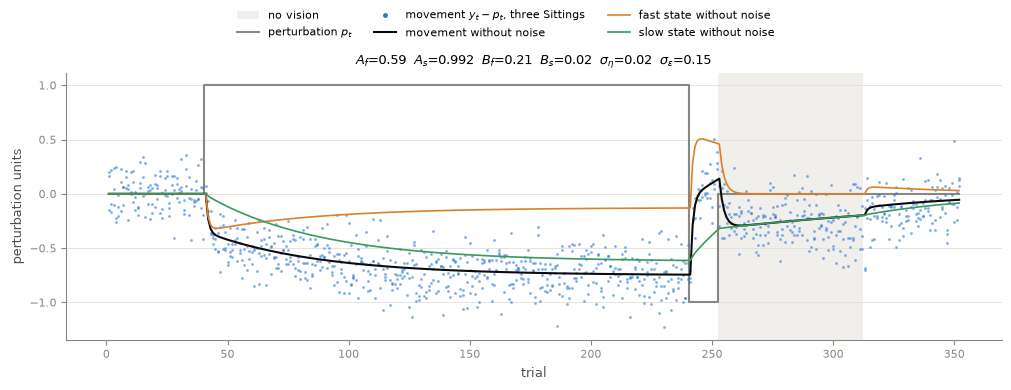

In [6]:
# [example-sittings] Three simulated Sittings, and the noise-free movement and states
theta_clean = (*theta_example[:4], tiny, tiny)
y_noisy = mdl.simulate_sitting(rng_example, theta_example, schedule, size=(3,))[0]["y"]
movement_noisy = y_noisy - p  # y is the error
observations_clean, truth_clean = mdl.simulate_sitting(rng_example, theta_clean, schedule)
movement_clean = observations_clean["y"] - p
x_fast_clean, x_slow_clean = truth_clean["x_fast"], truth_clean["x_slow"]

fig, ax = plt.subplots(figsize=(10, 3.8))
for start, stop in np.nonzero(np.diff(np.r_[1, v, 1]) != 0)[0].reshape(-1, 2):
    ax.axvspan(start + 0.5, stop + 0.5, color=shade, lw=0, label="no vision")
ax.step(trial, p, where="mid", color=muted, lw=1.5, label="perturbation $p_t$")
ax.plot(trial, movement_noisy.T, ".", color=blue, ms=2.5, alpha=0.4)
ax.plot([], [], ".", color=blue, ms=5, label="movement $y_t - p_t$, three Sittings")
ax.plot(trial, movement_clean, color="#0b0b0b", lw=1.5, label="movement without noise")
ax.plot(trial, x_fast_clean, color=orange, lw=1.2, label="fast state without noise")
ax.plot(trial, x_slow_clean, color=green, lw=1.2, label="slow state without noise")
ax.set_xlabel("trial")
ax.set_ylabel("perturbation units")
ax.set_title("$A_f$={}  $A_s$={}  $B_f$={}  $B_s$={}  $\\sigma_\\eta$={}  $\\sigma_\\varepsilon$={}".format(*theta_example))
ax.grid(axis="y", color=grid, lw=0.6)
fig.legend(loc="outside upper center", frameon=False, fontsize=8, ncols=3)
plt.show()

## [check-1] Check 1: the link to the one-state Model

With one planning noise shared by the two states, neither state can be switched off, so
the one-state Model is not a special case. The link is at the edge of the domain. When
$A_f = A_s = A$, adding the two state equations gives

$$
x_{t+1} = A\, x_t - (B_f + B_s)\, v_t\, y_t + (\eta^f_t + \eta^s_t), \qquad x_t = x^f_t + x^s_t
$$

which is the one-state Model with adaptation rate $B_f + B_s$ and planning noise
$\sqrt 2\,\sigma_\eta$. The Simulator requires $A_f$ below $A_s$, so $A_s$ is set to the
next number above $A$ that the computer can represent.

Without noise the two Simulators must then give the same movements (the two-state
Simulator's `y` minus the perturbation; the one-state Simulator's `y` as it is). With noise they use
their random numbers differently, so the comparison is of steady-state statistics, in
`[check-stationary]` below (its first row).

In [7]:
# [check-equal-retention] Noise-free movements: two-state with equal retentions against one-state
theta_two = (equal_A, np.nextafter(equal_A, 1), equal_Bf, equal_Bs, tiny, tiny)
theta_one = (equal_A, equal_Bf + equal_Bs, tiny, tiny)
movement_two = mdl.simulate_sitting(rng_equal, theta_two, schedule)[0]["y"] - p  # y is the error
movement_one = one_state.simulate_sitting(rng_equal, theta_one, schedule)[0]["y"]  # y is the movement

max_abs_diff_equal = np.abs(movement_two - movement_one).max()
assert max_abs_diff_equal < 1e-9
print(f"largest difference between the two Simulators: {max_abs_diff_equal:.1e}")

largest difference between the two Simulators: 1.4e-11


## [check-2] Check 2: it behaves like a two-state model

**Without noise.** Write $s_t = (x^f_t, x^s_t)$ and $b = (B_f, B_s)$. Within a Block,
with vision and perturbation $p$,

$$
s_{t+1} = S\, s_t - b\, p, \qquad
S = \begin{pmatrix} A_f - B_f & -B_f \\ -B_s & A_s - B_s \end{pmatrix}
$$

so $s_t = s^* + S^{\,t}(s_0 - s^*)$ with fixed point $s^* = -(I - S)^{-1} b\, p$. Without
vision $S$ is the diagonal matrix of the two retentions and nothing is added. The
closed form is computed Block by Block, each Block starting where the last one ended,
and compared with the Simulator run with negligible noise.

**Spontaneous recovery.** In the example Schedule the short reversal brings the movement
back toward zero mostly by pushing the fast state the other way, while the slow state
still holds most of the first adaptation. In the no-vision Block the fast state decays
within a few Trials and the movement returns toward the first adaptation before it
decays slowly (Smith et al. 2006). The Check is that the movement goes further from
zero, on the side of the first adaptation, after the no-vision Block starts.

In [8]:
# [check-noise-free] Closed-form states, Block by Block, against the noise-free simulation
Af, As, Bf, Bs = theta_example[:4]
b = np.array([Bf, Bs])
closed_form = []
s_start = np.zeros(2)  # both states start at 0 without noise
for trial_type, n in example_blocks:
    p_block, v_block = des.TRIAL_TYPES[trial_type]["p"], des.TRIAL_TYPES[trial_type]["v"]
    step = np.diag([Af, As]) - v_block * np.outer(b, np.ones(2))
    s_star = -np.linalg.solve(np.eye(2) - step, b) * p_block * v_block
    curve = np.array([s_star + np.linalg.matrix_power(step, k) @ (s_start - s_star) for k in range(n + 1)])
    closed_form.append(curve[:-1])  # the Block's n Trials
    s_start = curve[-1]  # the first Trial of the next Block
closed_form = np.concatenate(closed_form)

max_abs_diff_states = max(
    np.abs(closed_form[:, 0] - x_fast_clean).max(), np.abs(closed_form[:, 1] - x_slow_clean).max()
)
assert max_abs_diff_states < 1e-9
print(f"largest difference between closed form and simulation: {max_abs_diff_states:.1e}")

largest difference between closed form and simulation: 1.1e-11


In [9]:
# [check-spontaneous-recovery] The movement at the start of the no-vision Block and at its furthest
first_no_vision = int(np.nonzero(v == 0)[0][0])
movement_no_vision = movement_clean[v == 0]
recovery = pd.Series({
    "movement at the end of the first adaptation": movement_clean[np.nonzero(p == -1)[0][0] - 1],
    "movement on the first no-vision Trial": movement_no_vision[0],
    "furthest movement in the no-vision Block": movement_no_vision.min(),
    "Trials into the Block when it is reached": int(movement_no_vision.argmin()),
    "fast state on the first no-vision Trial": x_fast_clean[first_no_vision],
    "slow state on the first no-vision Trial": x_slow_clean[first_no_vision],
})
assert movement_no_vision.min() < movement_no_vision[0] - 0.1
recovery.round(3)

movement at the end of the first adaptation   -0.745
movement on the first no-vision Trial          0.139
furthest movement in the no-vision Block      -0.292
Trials into the Block when it is reached       9.000
fast state on the first no-vision Trial        0.458
slow state on the first no-vision Trial       -0.319
dtype: float64

**With noise.** Under a constant perturbation the two states settle into a stationary
fluctuation around the fixed point. With vision, $s_{t+1} - s^* = S\,(s_t - s^*) - b\,\varepsilon_t + \eta_t$,
so the covariance matrix $P$ of the states solves

$$
P = S\, P\, S^\top + \sigma_\varepsilon^2\, b\, b^\top + \sigma_\eta^2\, I
$$

and, with $\mathbf 1 = (1, 1)$,

$$
\sigma_y^2 = \mathbf 1^\top P\, \mathbf 1 + \sigma_\varepsilon^2, \qquad
R(1) = \frac{\mathbf 1^\top S\, P\, \mathbf 1 - \sigma_\varepsilon^2\, \mathbf 1^\top b}{\sigma_y^2}
$$

Without vision the same holds with $b = 0$ and $S$ the diagonal matrix of the
retentions. $P$ is computed by `scipy.linalg.solve_discrete_lyapunov`, which shares no
code with the Simulator. For the first parameter set, whose retentions are equal, the
one-state formulas of [docs/models/one_state.md](../../docs/models/one_state.md) are
computed as well, with $B = B_f + B_s$ and planning noise $\sqrt 2\,\sigma_\eta$.

For each parameter set, `n_sittings` Sittings are simulated under $p = 0$, with vision
and without. The first `t_burn` Trials are discarded; the standard deviation and the
lag-1 correlation are computed from the rest. Standard errors come from the spread
between `n_batches` groups of Sittings.

In [10]:
# [check-stationary] Simulated steady-state statistics against the linear-algebra values
rows = []
for theta in stationary_thetas:
    Af, As, Bf, Bs, s_eta, s_eps = theta
    for vision in (1, 0):
        T = t_burn + t_keep
        schedule_flat = {"p": np.zeros(T), "v": np.full(T, vision)}
        y = mdl.simulate_sitting(rng_stationary, theta, schedule_flat, size=(n_sittings,))[0]["y"]
        batches = y[:, t_burn:].reshape(n_batches, -1, t_keep)
        sd = batches.std(axis=(1, 2))
        r1 = np.array([np.corrcoef(batch[:, :-1].ravel(), batch[:, 1:].ravel())[0, 1] for batch in batches])

        b = vision * np.array([Bf, Bs])
        step = np.diag([Af, As]) - np.outer(b, np.ones(2))
        P = linalg.solve_discrete_lyapunov(step, s_eps**2 * np.outer(b, b) + s_eta**2 * np.eye(2))
        var_y = P.sum() + s_eps**2
        r1_expected = ((step @ P).sum() - s_eps**2 * b.sum()) / var_y

        if As - Af < 1e-9:  # equal retentions: the one-state formulas apply
            A_one, B_one, s_eta_one = Af, vision * (Bf + Bs), np.sqrt(2) * s_eta
            var_x = (s_eta_one**2 + B_one**2 * s_eps**2) / (1 - (A_one - B_one) ** 2)
            sd_one_state = np.sqrt(s_eps**2 + var_x)
            r1_one_state = ((A_one - B_one) * var_x - B_one * s_eps**2) / (s_eps**2 + var_x)
        else:
            sd_one_state = r1_one_state = np.nan

        se_sd, se_r1 = sd.std(ddof=1) / np.sqrt(n_batches), r1.std(ddof=1) / np.sqrt(n_batches)
        rows.append({
            "theta": tuple(round(float(value), 3) for value in theta),
            "vision": bool(vision),
            "sd simulated": sd.mean(),
            "sd expected": np.sqrt(var_y),
            "sd z": (sd.mean() - np.sqrt(var_y)) / se_sd,
            "R1 simulated": r1.mean(),
            "R1 expected": r1_expected,
            "R1 z": (r1.mean() - r1_expected) / se_r1,
            "sd one-state formula": sd_one_state,
            "R1 one-state formula": r1_one_state,
        })
check_stationary = pd.DataFrame(rows)
print("largest z-score in size:", check_stationary[["sd z", "R1 z"]].abs().max().max().round(2))
check_stationary.round(4)

largest z-score in size: 2.0


,theta,vision,sd simulated,sd expected,sd z,R1 simulated,R1 expected,R1 z,sd one-state formula,R1 one-state formula
0,"(0.95, 0.95, 0.15, 0.05, 0.03, 0.15)",True,0.1692,0.1693,-1.4693,0.0033,0.0045,-1.8106,0.1693,0.0045
1,"(0.95, 0.95, 0.15, 0.05, 0.03, 0.15)",False,0.2025,0.2024,0.2790,0.4281,0.4282,-0.0707,0.2024,0.4282
2,"(0.59, 0.992, 0.21, 0.02, 0.02, 0.15)",True,0.1694,0.1695,-1.0928,-0.0106,-0.0105,-0.0757,NaN,NaN
3,"(0.59, 0.992, 0.21, 0.02, 0.02, 0.15)",False,0.2195,0.2196,-0.0561,0.5237,0.5239,-0.0691,NaN,NaN
4,"(0.8, 0.98, 0.3, 0.05, 0.03, 0.1)",True,0.1236,0.1236,-0.0951,-0.0137,-0.0133,-0.3788,NaN,NaN
5,"(0.8, 0.98, 0.3, 0.05, 0.03, 0.1)",False,0.1880,0.1877,0.5071,0.6897,0.6890,0.4145,NaN,NaN
6,"(0.4, 0.995, 0.1, 0.01, 0.01, 0.2)",True,0.2086,0.2085,0.8838,-0.0336,-0.0324,-1.3154,NaN,NaN
7,"(0.4, 0.995, 0.1, 0.01, 0.01, 0.2)",False,0.2233,0.2239,-1.9955,0.1963,0.1999,-1.7583,NaN,NaN


## [check-3] Check 3: the Prior

The Prior starts from ranges for the four rates themselves (`[config]`, step 1) and is
translated in two further steps into six independent normals on unbounded scales:
$\mathrm{logit}(A_f)$, $\log d_A$, $\mathrm{logit}(B_f)$, $\log d_B$,
$\log\sigma_\varepsilon$ and $\log(\sigma_\eta/\sigma_\varepsilon)$, where
$d_A = \mathrm{logit}(A_s) - \mathrm{logit}(A_f)$ and
$d_B = \mathrm{logit}(B_f) - \mathrm{logit}(B_s)$ are positive. `sample_prior` draws
these and transforms them.

For $A_f$, $B_f$, $\sigma_\varepsilon$ and the noise ratio the translation is exact, so
the 2.5% and 97.5% quantiles of the draws must be the ends of the stated range. For the
slow rates $A_s$ and $B_s$ it is approximate (a normal plus a log-normal is not quite
normal), so their quantiles are expected to be close to the stated range and not equal.
The other rows have no stated range; they are what the Prior implies.

Under a constant perturbation $p$ with vision and no noise, the movement settles at
$-p\,K/(1+K)$ with $K = B_f/(1-A_f) + B_s/(1-A_s)$, and the slow state holds the share
$\big(B_s/(1-A_s)\big)/K$ of it.

In [11]:
# [check-prior-ranges] Quantiles of the drawn quantities against the stated ranges
theta = mdl.sample_prior(rng_prior, n_prior_draws, prior)
Af, As, Bf, Bs, s_eta, s_epsilon = theta.T
K = Bf / (1 - Af) + Bs / (1 - As)
drawn = {
    "Af": Af, "As": As, "Bf": Bf, "Bs": Bs,
    "s_epsilon": s_epsilon, "ratio": s_eta / s_epsilon, "s_eta": s_eta,
    "d_A": special.logit(As) - special.logit(Af), "d_B": special.logit(Bf) - special.logit(Bs),
    "fast time constant (trials)": -1 / np.log(Af),
    "slow time constant (trials)": -1 / np.log(As),
    "slow time constant / fast": np.log(Af) / np.log(As),
    "adaptation reached (fraction of p)": K / (1 + K),
    "slow state's share of it": Bs / (1 - As) / K,
}
stated = {
    "Af": range_Af, "As": range_As, "Bf": range_Bf, "Bs": range_Bs,
    "s_epsilon": range_s_epsilon, "ratio": range_ratio,
}
assert np.all((Af < As) & (Bf > Bs))
pd.DataFrame({
    name: {
        "stated 2.5%": stated.get(name, (np.nan, np.nan))[0],
        "drawn 2.5%": np.quantile(x, 0.025),
        "drawn median": np.median(x),
        "stated 97.5%": stated.get(name, (np.nan, np.nan))[1],
        "drawn 97.5%": np.quantile(x, 0.975),
    }
    for name, x in drawn.items()
}).T.round(4)

,stated 2.5%,drawn 2.5%,drawn median,stated 97.5%,drawn 97.5%
Af,0.7000,0.7001,0.8209,0.9000,0.9000
As,0.9500,0.9632,0.9920,0.9990,0.9993
Bf,0.1000,0.1000,0.1965,0.3500,0.3497
Bs,0.0010,0.0008,0.0079,0.0500,0.0383
s_epsilon,0.0667,0.0669,0.1491,0.3333,0.3333
ratio,0.0667,0.0667,0.1155,0.2000,0.2004
s_eta,NaN,0.0065,0.0172,NaN,0.0456
d_A,NaN,1.9149,3.2782,NaN,5.6124
d_B,NaN,2.0450,3.4006,NaN,5.6506
fast time constant (trials),NaN,2.8044,5.0676,NaN,9.4944


In [12]:
# [states-apart] How far apart the Prior keeps the two states, and how far from instability
stability = Bf / (1 + Af) + Bs / (1 + As)  # the Model is stable when this is below 1
pd.Series({
    "draws": n_prior_draws,
    "draws with a slow time constant less than twice the fast one": np.sum(np.log(Af) / np.log(As) < 2),
    "draws with Bs above half of Bf": np.sum(Bs > Bf / 2),
    "smallest slow time constant / fast": (np.log(Af) / np.log(As)).min(),
    "largest value of the stability quantity": stability.max(),
})

draws                                                           1000000.000000
draws with a slow time constant less than twice the fast one          0.000000
draws with Bs above half of Bf                                        0.000000
smallest slow time constant / fast                                    2.412611
largest value of the stability quantity                               0.375971
dtype: float64

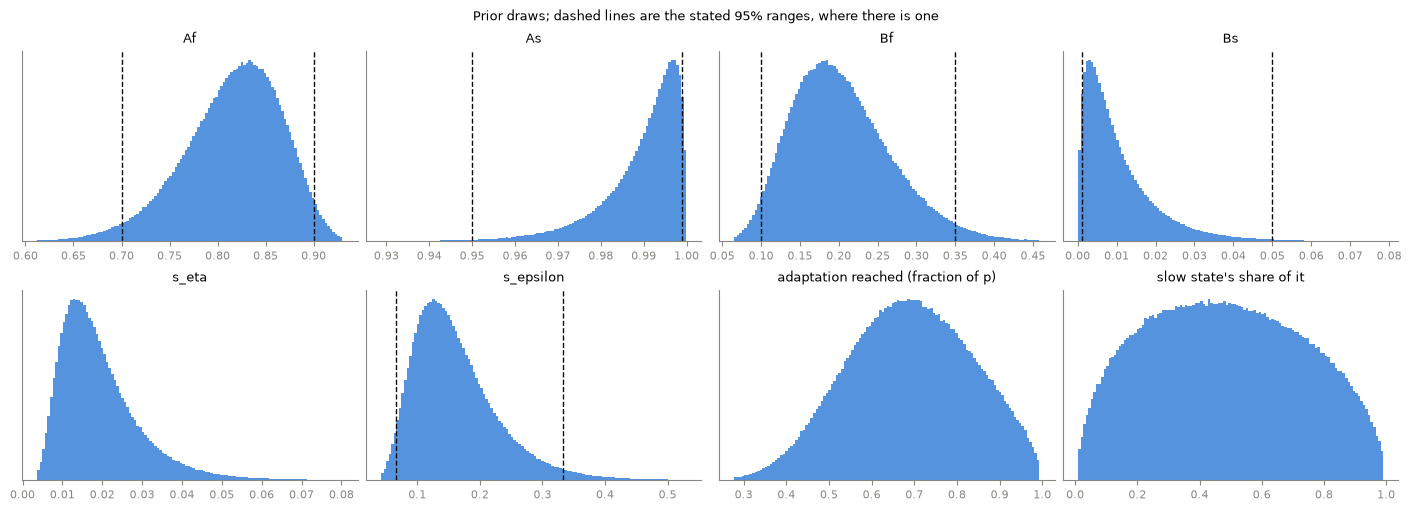

In [13]:
# [prior-histograms] What the Prior looks like on the natural scale
shown = ["Af", "As", "Bf", "Bs", "s_eta", "s_epsilon",
         "adaptation reached (fraction of p)", "slow state's share of it"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, name in zip(axes.flat, shown):
    x = drawn[name]
    ax.hist(x, bins=120, range=tuple(np.quantile(x, [0.001, 0.999])), color=blue, alpha=0.8)
    for edge in stated.get(name, ()):
        ax.axvline(edge, color="#0b0b0b", lw=1, ls="--")
    ax.set_title(name)
    ax.set_yticks([])
fig.suptitle("Prior draws; dashed lines are the stated 95% ranges, where there is one", fontsize=9)
plt.show()

**Simulated Sittings.** Each panel is one Sitting: its own Schedule from the Schedule
Design of the one-state Model, its own parameter values drawn from the Prior, and the
movements the Simulator produces. Grey bands are no-vision Blocks; the grey line is the
perturbation; dots are movements ($y - p$); the orange and green lines are the fast and slow
states (Ground Truth). A learner compensates by moving to $-p$.

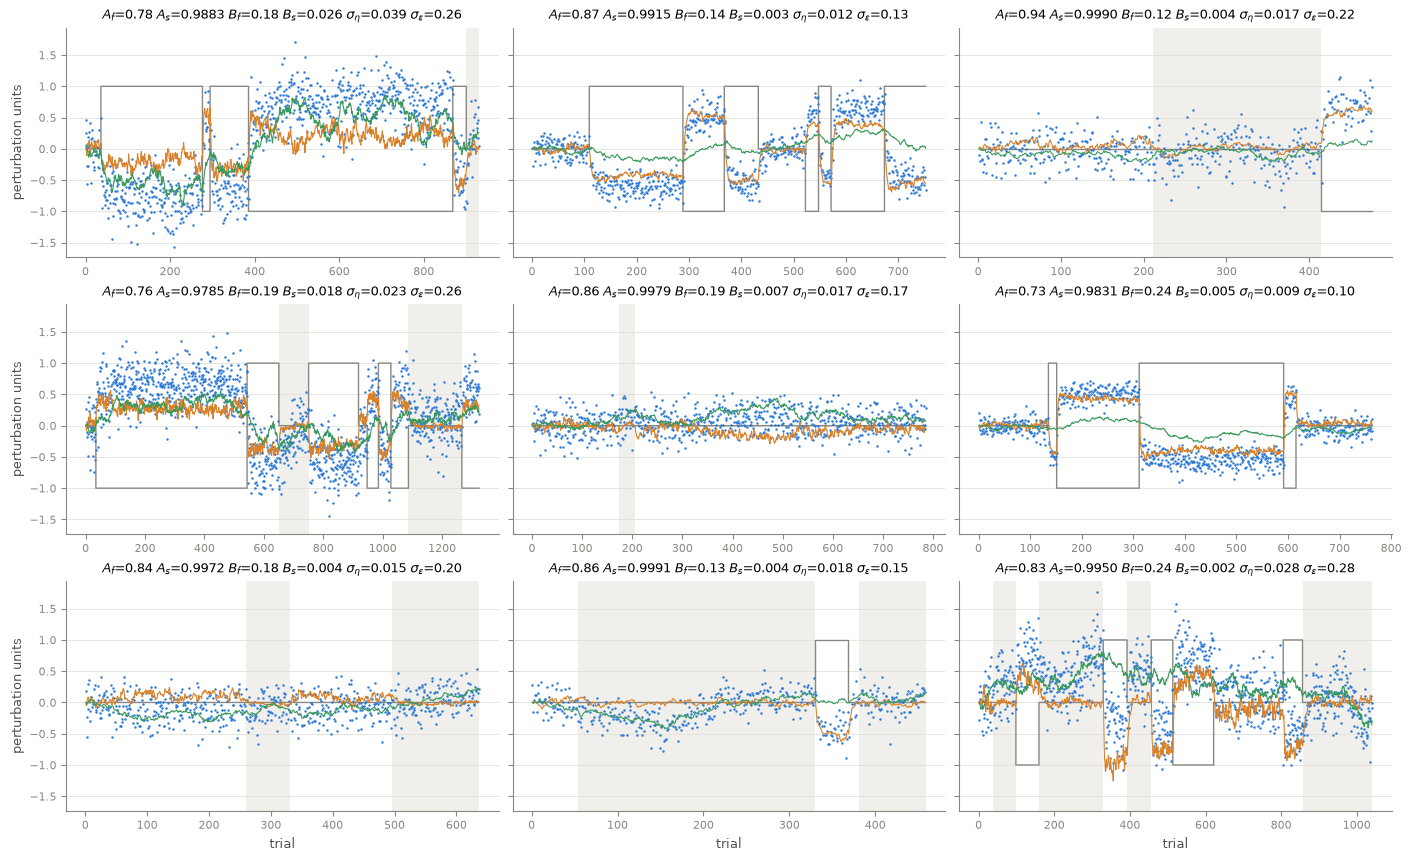

In [14]:
# [generated-sittings] Sittings from the Prior Sampler, the Schedule Generator and the Simulator
thetas = mdl.sample_prior(rng_generated, n_examples, prior)
fig, axes = plt.subplots(3, 3, figsize=(14, 8.5), sharey=True)
for ax, th in zip(axes.flat, thetas):
    schedule_drawn = des.sample_schedule(rng_generated, schedule_design)
    p_drawn, v_drawn = schedule_drawn["p"], schedule_drawn["v"]
    observations, truth = mdl.simulate_sitting(rng_generated, th, schedule_drawn)
    trial_drawn = np.arange(1, len(p_drawn) + 1)
    for start, stop in np.nonzero(np.diff(np.r_[1, v_drawn, 1]) != 0)[0].reshape(-1, 2):
        ax.axvspan(start + 0.5, stop + 0.5, color=shade, lw=0)
    ax.step(trial_drawn, p_drawn, where="mid", color=muted, lw=1)
    ax.plot(trial_drawn, observations["y"] - p_drawn, ".", color=blue, ms=1.5)
    ax.plot(trial_drawn, truth["x_fast"], color=orange, lw=0.8)
    ax.plot(trial_drawn, truth["x_slow"], color=green, lw=0.8)
    ax.set_title(
        "$A_f$={:.2f} $A_s$={:.4f} $B_f$={:.2f} $B_s$={:.3f} "
        "$\\sigma_\\eta$={:.3f} $\\sigma_\\varepsilon$={:.2f}".format(*th)
    )
    ax.grid(axis="y", color=grid, lw=0.6)
for ax in axes[-1]:
    ax.set_xlabel("trial")
for ax in axes[:, 0]:
    ax.set_ylabel("perturbation units")
plt.show()

## [results] What this shows

The Simulator's `y` is the error. "Movement" below is $y - p$.

1. **The link to the one-state Model: pass.** With equal retentions and no noise, the
   two Simulators differ by at most $1.4 \times 10^{-11}$ over the example Schedule
   (`[check-equal-retention]`). With noise, the two-state steady-state values for that
   parameter set are the one-state formulas' values to four decimals (standard
   deviation 0.1693 with vision and 0.2024 without; lag-1 correlation 0.0045 and
   0.4282), and the simulation agrees with both (first two rows of `[check-stationary]`).
2. **It behaves like a two-state model: pass.**
   - Without noise, the simulated states and the closed form differ by at most
     $1.1 \times 10^{-11}$ through all five Blocks (`[check-noise-free]`).
   - Spontaneous recovery: after 200 Trials of adaptation (movement $-0.75$) and 12
     Trials of reversal, the movement on the first no-vision Trial is $+0.14$, made of a
     fast state at $+0.46$ and a slow state at $-0.32$. Nine Trials later the movement
     is at $-0.29$: the fast state has decayed and the slow state's adaptation shows
     (`[check-spontaneous-recovery]`; the black line in the grey band of the first
     figure).
   - With noise, for all four parameter sets, with and without vision, the simulated
     standard deviation and lag-1 correlation agree with the linear-algebra values
     within Monte Carlo error: the largest of the 16 z-scores is 2.0 in size
     (`[check-stationary]`).
3. **Prior Sampler: pass.** Over a million draws (`[check-prior-ranges]`):
   - $A_f$, $B_f$, $\sigma_\varepsilon$ and the noise ratio have the stated ranges within
     sampling error.
   - The slow rates are close to the stated ranges, as expected of the approximate
     step: $A_s$ 0.963 to 0.9993 (stated 0.95 to 0.999), $B_s$ 0.0008 to 0.038 (stated
     0.001 to 0.05).
   - The states stay apart (`[states-apart]`): no draw has a slow time constant less
     than twice the fast one (the smallest ratio is 2.4), and none has $B_s$ above half
     of $B_f$. The stability quantity never exceeds 0.38, far below 1.
4. **Simulated Sittings:** for Opher to judge (`[generated-sittings]`).

**What the Prior implies** (`[check-prior-ranges]`): fast time constant 2.8 to 9.5
Trials; slow time constant 27 to about 1,400 Trials (median 124); the slow one 6 to 250
times the fast one; adaptation reached under a constant perturbation 41% to 95% of it
(median 69%), of which the slow state holds 6% to 93% (median 48%).

**Worth looking at in the simulated Sittings.** The two states are now easy to tell
apart: the fast state (orange) follows each Block within a few Trials and the slow state
(green) changes over tens to hundreds. Two things stand out.

- In Blocks shorter than the slow time constant the fast state does nearly all of the
  adapting, and the slow state has barely moved by the time the Block ends. Its
  parameters can only be learned from the longer Blocks.
- The slow state wanders. It has the same planning noise as the fast state on every
  Trial but forgets little of it, so with retention near 1 its noise adds up (standard
  deviation $\sigma_\eta/\sqrt{1 - A_s^2}$, about 22 times $\sigma_\eta$ at
  $A_s = 0.999$). In the bottom-right panel it drifts by about half a perturbation with
  no perturbation driving it. This follows from sharing one planning noise between the
  states.